# 02 · 实验可信度诊断与 ATE

## 本页要回答什么

公开数据的分组计数和处理前特征有哪些可观测差异？分类器能否从 X 中辨别 treatment？全量公开数据的 ATE 与结果可学习性是什么？

## 代码导航

- 主流程：run_pipeline.py 的 run()，阶段 5–6。
- 统一扫描：diagnostics.py 的 scan_raw_data()。
- 诊断与产物写入：diagnostics.py 的 srm_summary()、covariate_balance()、c2st()、update_experiment_diagnostics()。
- 全量 ATE：evaluation.py 的 aggregate_ate_from_audit()，由 pipeline_io.py 的 write_audit_artifacts() 保存。
- 结果可学习性：training.py 的 run_learnability_diagnostics() → diagnostics.py 的 learnability()。

## 结果文件

ate_full.csv、srm.json、balance.csv、c2st.csv、c2st_details.json、c2st_null.csv、learnability.csv。

本页读取已保存结果并解释本项目证据，不会自动重训正式模型。通用检验原理请查 DSDAHANDBOOK；这里重点关注计算函数、输出文件、样本范围和结论边界。

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
from IPython.display import display, Image, HTML
from criteo_uplift.pipeline_io import result_directory
RUN = result_directory('conversion_1000000_seed42', ROOT)
print('读取结果目录:', RUN.relative_to(ROOT))
manifest = json.loads(((RUN / 'manifest.json')).read_text())
print('分析对象:', manifest['primary_outcome'], '| 随机样本:', f"{manifest['sample_n']:,}")
print('seed:', manifest['seed'], '| 主预算:', manifest['selection']['primary_budget'])


读取结果目录: reports/published/conversion_1000000_seed42
分析对象: conversion | 随机样本: 1,000,000
seed: 42 | 主预算: 0.2


## 全量 ATE：结果文件从哪里来

读取 diagnostics/ate_full.csv。该文件由全量 audit 汇总计算，反映公开数据中 treatment 与 control 的描述性结果差异。表格保留概率尺度；图中转换为百分点（pp）展示。每十万人换算是对同一绝对差的尺度转换，不代表真实线上投放收益。

**代码链：** diagnostics.scan_raw_data() 生成全量 audit → evaluation.aggregate_ate_from_audit() 计算 → pipeline_io.write_audit_artifacts() 写入 ate_full.csv。

outcome,conversion,visit
n,13979592,13979592
n_control,2096937,2096937
n_treatment,11882655,11882655
response_control,0.001938,0.038201
response_treatment,0.003089,0.048543
ate,0.001152,0.010342
standard_error,0.000034,0.000146
ci_low,0.001085,0.010056
ci_high,0.001219,0.010629
p_value,7.308e-179,0.000e+00


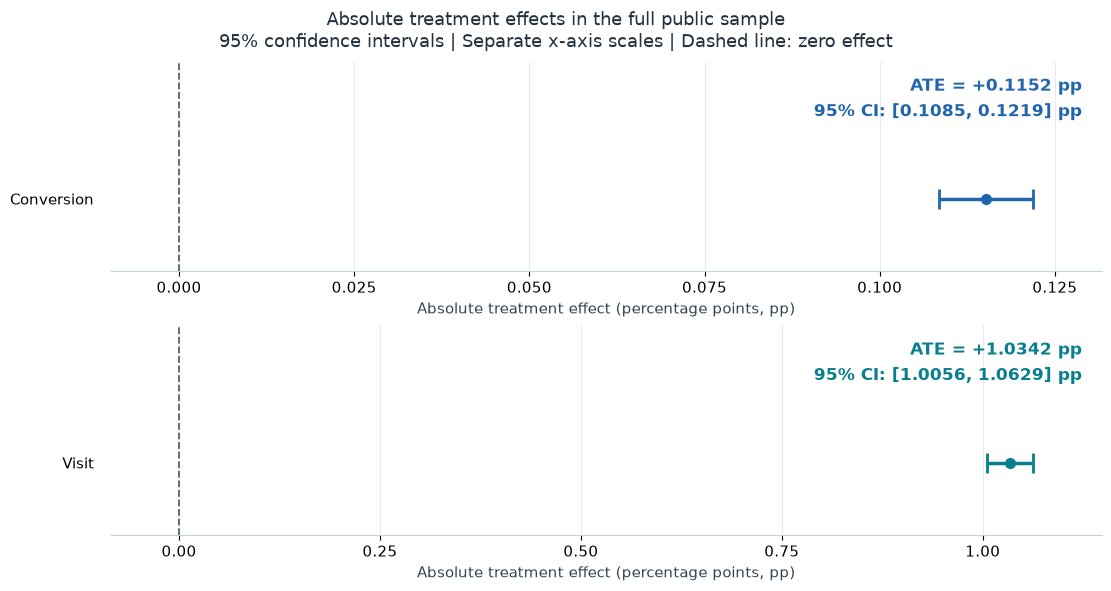

In [2]:
# 读取并展示已保存的全量 ATE 结果；本单元只调整展示，不重新计算统计量。

ate_df = pd.read_csv((RUN / 'diagnostics' / 'ate_full.csv'))
ate = ate_df  # 保留现有表格使用的变量名

ate_display = ate.set_index('outcome').T
display(
    ate_display.style
    .format('{:.6f}')
    .format(
        '{:.0f}',
        subset=pd.IndexSlice[['n', 'n_control', 'n_treatment'], :]
    )
    .format(
        '{:.3e}',
        subset=pd.IndexSlice[['p_value'], :]
    )
)

# 从当前表格现场绘图；原始列保持比例单位，绘图副本转换为百分点（pp）。
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

ate_plot = (
    ate_df.set_index('outcome')
    .loc[['conversion', 'visit'], ['ate', 'ci_low', 'ci_high']]
    .mul(100) #转换成pp值
)

with plt.rc_context( # 使用with:设置临时的图片样式参数
    {
        'font.family': 'DejaVu Sans',
        'font.size': 11,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.spines.left': False,
        'axes.edgecolor': '#C8D0D8',
        'axes.labelcolor': '#344454',
        'text.color': '#23313F',
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    }
):
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(11, 5.8),
        sharex=False,
        constrained_layout=True,
    )
    fig.suptitle(
        'Absolute treatment effects in the full public sample\n'
        '95% confidence intervals | Separate x-axis scales | Dashed line: zero effect',
        fontsize=13,
    )

    for ax, (outcome, row), color in zip(
        axes,
        ate_plot.iterrows(),
        ['#2166AC', '#087F8C'],
    ):
        ax.axvline(
            0,
            color='#536170',
            linestyle='--',
            linewidth=1.3,
            zorder=2,
        )
        ax.errorbar(
            x=[row['ate']],
            y=[0],
            xerr=[
                [row['ate'] - row['ci_low']],
                [row['ci_high'] - row['ate']],
            ],
            fmt='o',
            color=color,
            markersize=7,
            elinewidth=2.5,
            capsize=7,
            capthick=2,
            zorder=3,
        )

        # 每个子图独立缩放，但始终包含零点、点估计和完整 CI；保持线性坐标。
        left = min(0.0, row['ci_low'], row['ate'])
        right = max(0.0, row['ci_high'], row['ate'])
        span = right - left
        padding = 0.08 * span if span > 0 else 0.01
        ax.set_xlim(
            left - padding,
            right + padding,
        )

        ax.set_ylim(-0.45, 0.85)
        ax.set_yticks(
            [0],
            [outcome.capitalize()],
        )
        ax.tick_params(axis='y', length=0, pad=12)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
        
        ax.set_xlabel('Absolute treatment effect (percentage points, pp)')
        ax.set_axisbelow(True)
        ax.grid(axis='x', color='#E6EBEF', linewidth=0.8)

        # 标注使用绘图区相对坐标，放在点和 CI 上方，避免遮挡。
        ax.text(
            0.98,
            0.94,
            f"ATE = {row['ate']:+.4f} pp\n"
            f"95% CI: [{row['ci_low']:.4f}, {row['ci_high']:.4f}] pp",
            transform=ax.transAxes,
            ha='right',
            va='top',
            fontsize=12,
            fontweight='bold',
            color=color,
            linespacing=1.5,
        )

    plt.show()


## 1. SRM：公开计数与 85% 外部参考比例

**实现位置：** diagnostics.py 的 srm_summary()；输出 srm.json。

85% 来自数据集公开资料，是对发布数据计数的外部参考比例。本检查只比较公开计数与参考比例的一致性，不能据此宣布原始线上实验通过 SRM，也不能证明随机化成立。结果表中的 scope、观测比例、参考比例和 p 值应一起阅读。

In [3]:
srm = json.loads(
    ((RUN / 'diagnostics' / 'srm.json')).read_text()
)
display(
    pd.DataFrame([srm])[
        ['scope', 'n_treatment', 'n_control', 'observed_ratio',
         'expected_ratio', 'chi2', 'pvalue', 'status']
    ].style.format(
        {'observed_ratio': '{:.10f}', 'expected_ratio': '{:.2f}',
         'chi2': '{:.6e}', 'pvalue': '{:.6f}'}
    )
)
print(srm['interpretation'])
print('85%独立参考来源：', srm['reference_source'])

,scope,n_treatment,n_control,observed_ratio,expected_ratio,chi2,pvalue,status
0,full_published_dataset,11882655,2096937,0.8500001288,0.85,1.817776e-06,0.998924,computed


公开数据分配计数与85%外部参考比例的一致性；不验证原始线上实验SRM或随机化。
85%独立参考来源： https://arxiv.org/html/2111.10106#S3


## 2. SMD / KS：处理前特征的单变量差异

**实现位置：** diagnostics.py 的 covariate_balance()；输出 balance.csv 和 figures/balance.png。

计算直接基于全量原始 CSV 的 float64 值，不使用 float32 建模缓存，也不静默删除记录。表格按绝对 SMD 排序，方便先看差异最大的特征；SMD 的经验阈值不是通用硬性通过标准。KS 的 p 值未经多重校正，样本量很大时应同时观察统计量大小和数据背景。

单变量平衡不代表联合分布一致。匿名特征也不能验证真实用户级隔离或特征生成时间。

,feature,n_treatment,n_control,mean_treatment,mean_control,smd,abs_smd,ks_statistic,ks_pvalue,scope,representation
3,f3,11882655,2096937,4.169412,4.232821,-0.048836,0.048836,0.013794,5.007e-295,full_published_dataset,raw_csv_float64
6,f6,11882655,2096937,-4.182792,-3.999880,-0.040448,0.040448,0.013069,7.419e-265,full_published_dataset,raw_csv_float64
5,f5,11882655,2096937,4.026602,4.039339,-0.030557,0.030557,0.006099,5.198e-58,full_published_dataset,raw_csv_float64
9,f9,11882655,2096937,16.052589,15.886253,+0.024001,0.024001,0.007125,5.184e-79,full_published_dataset,raw_csv_float64
1,f1,11882655,2096937,10.070337,10.067935,+0.023994,0.023994,0.002662,2.119e-11,full_published_dataset,raw_csv_float64
8,f8,11882655,2096937,3.933392,3.934652,-0.022433,0.022433,0.008334,5.837e-108,full_published_dataset,raw_csv_float64
7,f7,11882655,2096937,5.105555,5.080284,+0.021270,0.021270,0.006099,5.198e-58,full_published_dataset,raw_csv_float64
10,f10,11882655,2096937,5.333660,5.331898,+0.010563,0.010563,0.002415,1.882e-09,full_published_dataset,raw_csv_float64
4,f4,11882655,2096937,10.339245,10.336526,+0.007966,0.007966,0.002412,1.959e-09,full_published_dataset,raw_csv_float64
0,f0,11882655,2096937,19.614755,19.651705,-0.006866,0.006866,0.008950,1.913e-124,full_published_dataset,raw_csv_float64


全量最大 |SMD|：f3 = 0.048836；最大 KS- statistic：f3 = 1.379e-02


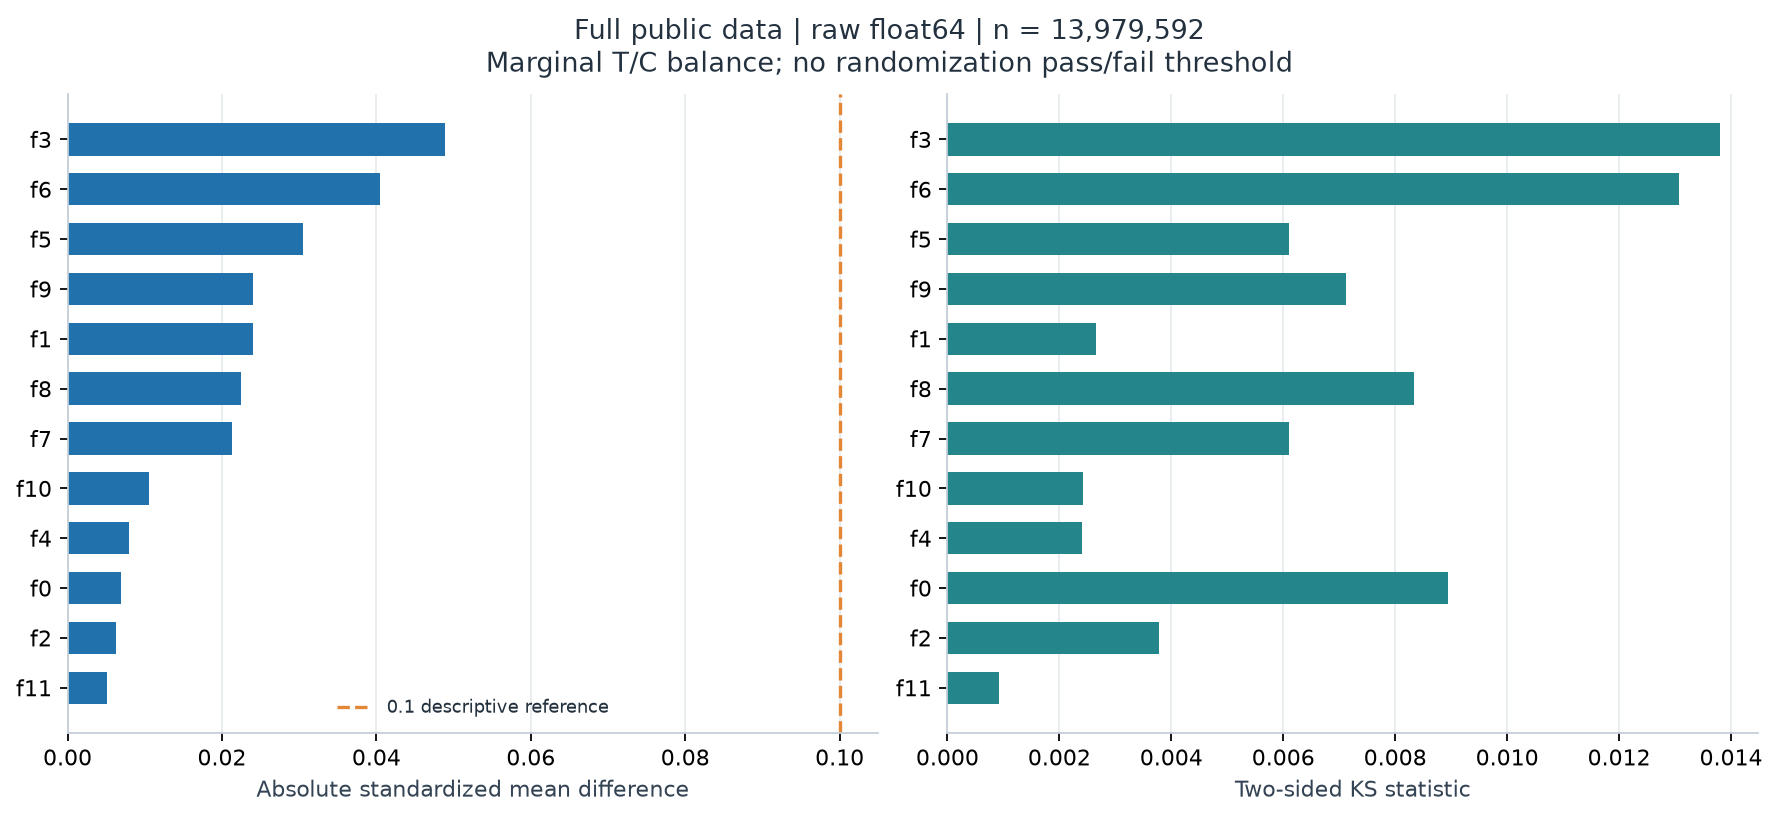

In [4]:
balance_public = pd.read_csv(
    (RUN / 'diagnostics' / 'balance.csv')
)
assert balance_public['scope'].eq('full_published_dataset').all()
assert balance_public['n_treatment'].eq(srm['n_treatment']).all()
assert balance_public['n_control'].eq(srm['n_control']).all()
display(
    balance_public.drop(columns='source_sha256').sort_values('abs_smd', ascending=False).style.format(
        {'mean_treatment': '{:.6f}', 'mean_control': '{:.6f}',
         'smd': '{:+.6f}', 'abs_smd': '{:.6f}',
         'ks_statistic': '{:.6f}', 'ks_pvalue': '{:.3e}'}
    )
)
max_smd = balance_public.loc[balance_public['abs_smd'].idxmax()]
max_ks = balance_public.loc[balance_public['ks_statistic'].idxmax()]
print(
    f"全量最大 |SMD|：{max_smd['feature']} = {max_smd['abs_smd']:.6f}；"
    f"最大 KS- statistic：{max_ks['feature']} = {max_ks['ks_statistic']:.3e}"
)
display(
    Image(
        filename=str(
            RUN / 'figures/balance.png'
        )
    )
)


## 3. C2ST：两组联合可区分性诊断

**实现位置：** diagnostics.py 的 update_experiment_diagnostics() 调用 c2st()；输出 c2st.csv、c2st_details.json、c2st_null.csv。

本项目默认从全量来源分别抽取 10,000 control 和 10,000 treatment，形成 1:1 的诊断样本；这不是总体 85:15 比例，也不是正式 train/validation/test。内部按 treatment 分层做 70/30 训练/留出划分，使用 Logistic Regression 与 HistGradientBoosting。置换时分别打乱内部训练集和留出集的标签，并完整重拟合模型；两模型 p 值再做 Holm 校正。

阅读结果时依次看留出 AUC、Holm 校正 p 值、置换次数和 p 值分辨率。AUC 接近 0.5 表示当前分类器难以区分两组；不显著不证明联合分布完全相同或随机化成立。

,model,sample_n,n_control,n_treatment,roc_auc,pvalue_holm,permutations,pvalue_resolution,reading
0,logistic,20000,10000,10000,0.5177,0.012,499,0.0020,检测到当前设计下的联合可区分性证据：需调查
1,hgb,20000,10000,10000,0.5101,0.076,499,0.0020,当前样本/分类器未发现足够证据；不等于证明分布相同


,scope,train_n_control,train_n_treatment,holdout_n_control,holdout_n_treatment,seed,metric,multiplicity
0,full_source_arm_balanced_sample,7000,7000,3000,3000,42,one-sided ROC AUC,Holm across two prespecified classifiers


抽样方式： independent uniform-priority reservoir without replacement within each arm
实际置换次数： 499
p 值分辨率： 0.002
数据来源： e4d7c710ca1f38e523309d0f8a0745d1b53e7392d51f20d1088b6cfeaef222ef


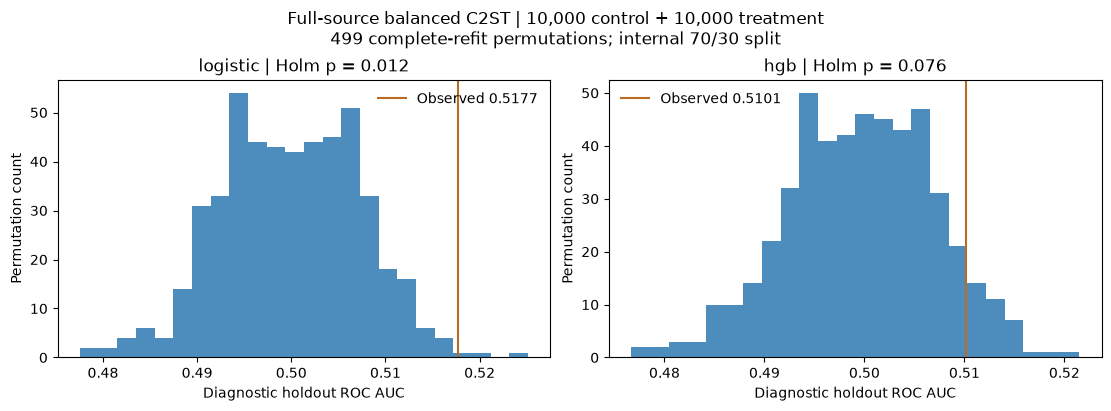

In [5]:
c2st_public = pd.read_csv(
    (RUN / 'diagnostics' / 'c2st.csv')
)
c2st_details = json.loads(
    ((RUN / 'diagnostics' / 'c2st_details.json')).read_text()
)
assert c2st_public['scope'].eq('full_source_arm_balanced_sample').all()
c2st_display = c2st_public[
    ['model', 'sample_n', 'n_control', 'n_treatment',
     'roc_auc', 'pvalue_holm', 'permutations', 'pvalue_resolution']
].copy()
c2st_display['reading'] = np.where(
    c2st_display['pvalue_holm'] < 0.05,
    '检测到当前设计下的联合可区分性证据：需调查',
    '当前样本/分类器未发现足够证据；不等于证明分布相同',
)
display(c2st_display.style.format(
    {'roc_auc': '{:.4f}', 'pvalue_holm': '{:.3f}', 'pvalue_resolution': '{:.4f}'}
))
display(
    pd.DataFrame(
        [{key: c2st_details[key] for key in
          ['scope', 'train_n_control', 'train_n_treatment',
           'holdout_n_control', 'holdout_n_treatment', 'seed', 'metric', 'multiplicity']}]
    )
)
print('抽样方式：', c2st_details['sampling'])
print('实际置换次数：', c2st_details['permutations'])
print('p 值分辨率：', c2st_details['pvalue_resolution'])
print('数据来源：', c2st_details['source']['sha256'])
# 直接从原来的 c2st_null.csv 现场绘制置换零分布。
null = pd.read_csv(
    (RUN / 'diagnostics' / 'c2st_null.csv')
)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True,
)
for ax, row in zip(axes, c2st_public.itertuples()):
    ax.hist(
        null.loc[null['model'] == row.model, 'roc_auc'],
        bins=24, color='#2171ad', alpha=.8,
    )
    ax.axvline(
        row.roc_auc, color='#ba6b24', label=f'Observed {row.roc_auc:.4f}',
    )
    ax.set_title(f'{row.model} | Holm p = {row.pvalue_holm:.3f}')
    ax.set_xlabel('Diagnostic holdout ROC AUC')
    ax.set_ylabel('Permutation count')
    ax.legend(frameon=False)
fig.suptitle(
    f"Full-source balanced C2ST | {c2st_details['n_control']:,} control + "
    f"{c2st_details['n_treatment']:,} treatment\n"
    f"{c2st_details['permutations']} complete-refit permutations; internal 70/30 split"
)
plt.show()

## 4. 综合结论与边界

以下摘要由保存的诊断产物动态生成。统计显著性不等于业务重要性；未发现明显差异也不等于证明随机化。公开数据经过发布处理，匿名字段无法恢复用户身份、真实实验分块、跨实验结构或特征的真实生成时间。

这些结果属于对已查看公开数据的描述性诊断，不是新的独立测试集验证；不会用于回头调整正式模型选择、特征删除或数据切分。

In [6]:
srm_statement = (
    '未检测到公开计数偏离85%参考比例的证据'
    if srm['pvalue'] >= 0.05
    else '公开计数与85%参考比例存在统计差异，需要调查发布机制'
)
print(f"全量 SRM 参考检查：{srm_statement}（p={srm['pvalue']:.6f}）。")
print(
    f"全量单变量差异：最大 |SMD|={max_smd['abs_smd']:.6f} ({max_smd['feature']})，"
    f"最大 KS={max_ks['ks_statistic']:.6f} ({max_ks['feature']})；"
    '请结合量级解释，不以显著性或0.1作为随机化通过标准。'
)
for row in c2st_public.itertuples():
    finding = (
        '当前设计下检测到联合可区分性的证据，需调查'
        if row.pvalue_holm < 0.05
        else '当前样本规模与分类器未检测到足够联合可区分性证据'
    )
    print(f"全量来源 C2ST / {row.model}：{finding}（Holm p={row.pvalue_holm:.3f}）。")
print('不能据此证明随机化、联合分布完全一致、用户级隔离或真实投放收益。')


全量 SRM 参考检查：未检测到公开计数偏离85%参考比例的证据（p=0.998924）。
全量单变量差异：最大 |SMD|=0.048836 (f3)，最大 KS=0.013794 (f3)；请结合量级解释，不以显著性或0.1作为随机化通过标准。
全量来源 C2ST / logistic：当前设计下检测到联合可区分性的证据，需调查（Holm p=0.012）。
全量来源 C2ST / hgb：当前样本规模与分类器未检测到足够联合可区分性证据（Holm p=0.076）。
不能据此证明随机化、联合分布完全一致、用户级隔离或真实投放收益。


## 结果可学习性：特征是否包含结果预测信息

**实现位置：** training.py 的 run_learnability_diagnostics() 调用 diagnostics.learnability()；输出 learnability.csv。

这里比较 Dummy、Logistic 和 HistGradientBoosting 对 visit / conversion 的预测能力，并查看整体样本与两个 treatment 臂。结果可预测不等于 CATE 可预测，也不能替代策略增量、AUUC 或 Qini。

In [7]:
learning = pd.read_csv((RUN / 'diagnostics' / 'learnability.csv'))
display(learning[[c for c in ['scope', 'outcome', 'n_train', 'n_validation', 'positive_rate_train', 'positive_rate_validation', 'model', 'roc_auc', 'average_precision', 'log_loss', 'brier', 'status'] if c in learning.columns]])

,scope,outcome,n_train,n_validation,positive_rate_train,positive_rate_validation,model,roc_auc,average_precision,log_loss,brier,status
0,whole,visit,600000,200000,0.046762,0.046870,dummy,0.500000,0.046870,0.189194,0.044673,computed
1,whole,visit,600000,200000,0.046762,0.046870,logistic,0.931984,0.478526,0.111607,0.031408,computed
2,whole,visit,600000,200000,0.046762,0.046870,hgb,0.944163,0.504059,0.105148,0.030132,computed
3,treatment,visit,510246,170083,0.048379,0.048858,dummy,0.500000,0.048858,0.195143,0.046472,computed
4,treatment,visit,510246,170083,0.048379,0.048858,logistic,0.932179,0.487910,0.114608,0.032359,computed
5,treatment,visit,510246,170083,0.048379,0.048858,hgb,0.943901,0.512811,0.108101,0.031072,computed
6,control,visit,89754,29917,0.037569,0.035565,dummy,0.500000,0.035565,0.153640,0.034304,computed
7,control,visit,89754,29917,0.037569,0.035565,logistic,0.928838,0.424461,0.092979,0.025548,computed
8,control,visit,89754,29917,0.037569,0.035565,hgb,0.944837,0.447234,0.087337,0.024435,computed
9,whole,conversion,600000,200000,0.002882,0.002880,dummy,0.500000,0.002880,0.019724,0.002872,computed


## 仅更新诊断，不重训模型

在已有实验目录上执行：

~~~bash
python run_pipeline.py --diagnostics-only --output artifacts/conversion_1000000_seed42
~~~

该模式会原位更新 SRM、SMD/KS、C2ST 诊断文件和报告；不重新切分、不重训正式 uplift 模型，也不改写 ATE 和策略评价。默认 C2ST 每组 10,000 行、seed=42、499 次完整重拟合置换；实际配置以当前 manifest 与 c2st_details.json 为准。

完整执行路径见 ../docs/PROJECT_PIPELINE.md；文件和指标映射见 ../docs/RESULTS_GUIDE.md。